In [1]:
using LinearAlgebra
using Plots

In [2]:
g_L = 1/0.023
Ybus = [g_L -g_L; -g_L g_L]

2×2 Matrix{Float64}:
  43.4783  -43.4783
 -43.4783   43.4783

In [12]:
# datos para la estimacion
nd = 200
VD = 0.01*randn(2,nd) .+ 1
ID = Ybus*VD + randn(2,nd)*1E-3
VD = VD + randn(2,nd)*1E-5
Yest = ID*VD'*inv(VD*VD')

2×2 Matrix{Float64}:
  43.4783  -43.4782
 -43.4809   43.4807

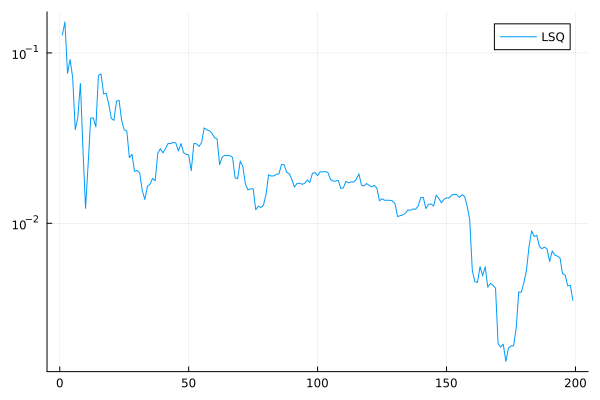

In [13]:
err = zeros(nd)
for k = 2:nd
    local IDL = ID[:,1:k]
    local VDL = VD[:,1:k]
    Yest = IDL*VDL'*inv(VDL*VDL')
    err[k] = norm(Yest-Ybus)
end
p1 = plot(err[2:end],yaxis=:log10,label="LSQ")
display(p1)

In [5]:
# Formulacion vectorial
H = kron(VD',one(Ybus))
φ = H\vec(ID)

4-element Vector{Float64}:
  43.480468274077104
 -43.484542436781624
 -43.48039035314324
  43.48451052093369

In [6]:
# Formulacion usando la matriz de duplicacion para que sea simetrica
D = [1 0 0;0 1 0; 0 1 0; 0 0 1]
φ = (H*D)\vec(ID)

3-element Vector{Float64}:
  43.48254414025123
 -43.48246576690139
  43.48243465476004

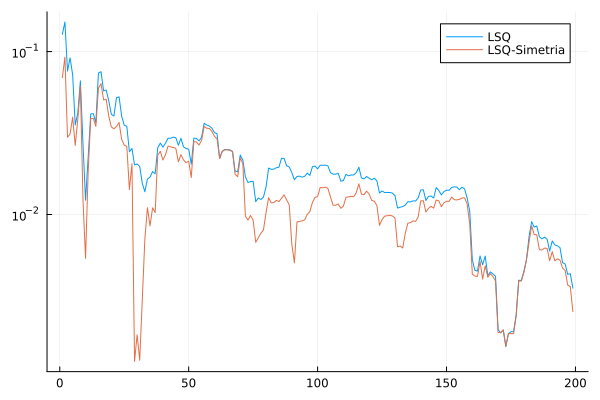

In [14]:
# Veamos el efecto en varios datos
err = zeros(nd)
vecY = vec(Ybus)
for k = 2:nd
    local IDL = ID[:,1:k]
    local VDL = VD[:,1:k]
    local H = kron(VDL',one(Ybus))
    local φ = (H*D)\vec(IDL)
    err[k] = norm(D*φ-vecY)
end
p1 = plot!(err[2:end],yaxis=:log10,label="LSQ-Simetria")
display(p1)